# 🔬 Hyperparameter Tuning & Cross-Validation Master Guide

This notebook covers all strategies for hyperparameter optimization and cross-validation:

1. **Cross-Validation Strategies**:
   - `KFold` (Standard CV)
   - `StratifiedKFold` (Preserves class proportions — essential for classification)
   - `cross_validate` vs `cross_val_score` (Multi-metric evaluation + timing)
   - `RepeatedStratifiedKFold` (Higher stability with multiple seeds)
   - `TimeSeriesSplit` (Temporal validation without future data leakage)
   - `LeaveOneOut` (LOOCV for tiny datasets)
2. **Hyperparameter Tuning Methods**:
   - `GridSearchCV` (Exhaustive search over discrete parameter grids)
   - `RandomizedSearchCV` (Stochastic search over continuous/discrete distributions)
   - Inspecting search results (`cv_results_`, `best_params_`, `best_score_`, `best_estimator_`)
3. **Visual Diagnostics**:
   - **Validation Curve**: Diagnosing Underfitting (Bias) vs Overfitting (Variance)
   - **Learning Curve**: Evaluating impact of training set size
   - **Hyperparameter Heatmap**: Visualizing interaction between parameters
4. **Nested Cross-Validation**:
   - Unbiased performance estimation combining outer validation and inner tuning
5. **Exam Ready Parameter Grids**:
   - Copy-paste grids for Logistic Regression, Decision Tree, Random Forest, SVM, and KNN


## 0. Setup and Data Preparation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Visual styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4.5)

# Load Breast Cancer (Classification)
cancer = load_breast_cancer(as_frame=True)
X, y = cancer.data, cancer.target

# Train-Test Split (80% Train, 20% Held-out Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Dataset: {X.shape[0]} samples, {X.shape[1]} features")
print(f"Training set: {X_train.shape[0]} samples, Test set: {X_test.shape[0]} samples")
print(f"Class Distribution: {np.bincount(y)} (0: Malignant, 1: Benign)")

Dataset: 569 samples, 30 features
Training set: 455 samples, Test set: 114 samples
Class Distribution: [212 357] (0: Malignant, 1: Benign)


---
## 1. Cross-Validation Strategies

### Why Cross-Validation?
A single train/test split can be biased depending on how the data was randomly partitioned. Cross-validation splits data into $K$ folds, training on $K-1$ folds and evaluating on the remaining fold, rotating until all folds have served as the test set.

```python
from sklearn.model_selection import (
    KFold, StratifiedKFold, RepeatedStratifiedKFold,
    TimeSeriesSplit, LeaveOneOut, cross_val_score, cross_validate
)
```


In [2]:
from sklearn.model_selection import (
    KFold, StratifiedKFold, RepeatedStratifiedKFold,
    cross_val_score, cross_validate
)
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(max_iter=1000, random_state=42)

# 1. Standard K-Fold (Unstratified)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
scores_kf = cross_val_score(clf, X_train_scaled, y_train, cv=kf, scoring='accuracy')

# 2. Stratified K-Fold (Maintains class proportions in every fold)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores_skf = cross_val_score(clf, X_train_scaled, y_train, cv=skf, scoring='accuracy')

# 3. Repeated Stratified K-Fold (e.g., 5 folds repeated 3 times = 15 total fits)
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
scores_rskf = cross_val_score(clf, X_train_scaled, y_train, cv=rskf, scoring='accuracy')

print("=== 1.1 Comparison of Cross-Validation Splits ===")
print(f"Standard K-Fold (5 folds):            {scores_kf.mean()*100:.2f}% (± {scores_kf.std()*100:.2f}%)")
print(f"Stratified K-Fold (5 folds):          {scores_skf.mean()*100:.2f}% (± {scores_skf.std()*100:.2f}%)")
print(f"Repeated Stratified K-Fold (15 runs): {scores_rskf.mean()*100:.2f}% (± {scores_rskf.std()*100:.2f}%)")

=== 1.1 Comparison of Cross-Validation Splits ===
Standard K-Fold (5 folds):            97.14% (± 2.37%)
Stratified K-Fold (5 folds):          97.80% (± 0.98%)
Repeated Stratified K-Fold (15 runs): 97.51% (± 1.02%)


### 1.2 Multi-Metric Evaluation with `cross_validate`
Unlike `cross_val_score` which only returns one metric, `cross_validate` computes:
- Multiple scoring metrics simultaneously (e.g. `accuracy`, `precision`, `recall`, `f1`, `roc_auc`).
- Fit times and scoring times (helps benchmark training latency).
- Training scores (`return_train_score=True`) to detect overfitting.


In [3]:
# Multiple metrics with cross_validate
metrics_dict = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

cv_results = cross_validate(
    clf, X_train_scaled, y_train,
    cv=skf,
    scoring=metrics_dict,
    return_train_score=True
)

summary_cv = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Train Score (Mean)': [
        cv_results['train_accuracy'].mean(),
        cv_results['train_precision'].mean(),
        cv_results['train_recall'].mean(),
        cv_results['train_f1'].mean(),
        cv_results['train_roc_auc'].mean()
    ],
    'Validation Score (Mean)': [
        cv_results['test_accuracy'].mean(),
        cv_results['test_precision'].mean(),
        cv_results['test_recall'].mean(),
        cv_results['test_f1'].mean(),
        cv_results['test_roc_auc'].mean()
    ],
    'Validation Std': [
        cv_results['test_accuracy'].std(),
        cv_results['test_precision'].std(),
        cv_results['test_recall'].std(),
        cv_results['test_f1'].std(),
        cv_results['test_roc_auc'].std()
    ]
})

print("=== Multi-Metric 5-Fold Cross-Validation Summary ===")
print(summary_cv.to_string(index=False))
print(f"\nAverage Model Fit Time:  {cv_results['fit_time'].mean()*1000:.2f} ms")
print(f"Average Score Eval Time: {cv_results['score_time'].mean()*1000:.2f} ms")

=== Multi-Metric 5-Fold Cross-Validation Summary ===
   Metric  Train Score (Mean)  Validation Score (Mean)  Validation Std
 Accuracy            0.989011                 0.978022        0.009829
Precision            0.986117                 0.979472        0.016229
   Recall            0.996491                 0.985965        0.013129
 F1-Score            0.991274                 0.982544        0.007752
  ROC-AUC            0.997633                 0.995666        0.004836

Average Model Fit Time:  19.55 ms
Average Score Eval Time: 35.62 ms


---
## 2. Hyperparameter Tuning Methods

```python
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
```

- **`GridSearchCV`**: Exhaustively tests every single possible combination in `param_grid`.
- **`RandomizedSearchCV`**: Randomly samples $N$ combinations (`n_iter`) from `param_distributions`. Much faster for large or continuous spaces.


In [4]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import randint

# ---------------------------------------------
# 2.1 GridSearchCV (Exhaustive Discrete Grid)
# ---------------------------------------------
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [3, 5, 8, None],
    'min_samples_split': [2, 5],
    'criterion': ['gini', 'entropy']
}

grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=1
)

grid.fit(X_train_scaled, y_train)

print("=== 2.1 GridSearchCV Results ===")
print(f"Total Combinations Tested: {len(grid.cv_results_['params'])}")
print(f"Best Parameters:           {grid.best_params_}")
print(f"Best 5-Fold CV Accuracy:   {grid.best_score_ * 100:.2f}%")
print(f"Test Accuracy on Unseen:   {grid.score(X_test_scaled, y_test) * 100:.2f}%\n")

# ---------------------------------------------
# 2.2 RandomizedSearchCV (Stochastic Sampling)
# ---------------------------------------------
param_dist = {
    'n_estimators': randint(30, 150),       # Random integer between 30 and 150
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': randint(2, 10),
    'max_features': ['sqrt', 'log2', None]
}

random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=param_dist,
    n_iter=15,          # Exactly 15 randomly chosen configurations
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=1
)

random_search.fit(X_train_scaled, y_train)

print("=== 2.2 RandomizedSearchCV Results ===")
print(f"Iterations Sampled:      {random_search.n_iter}")
print(f"Best Parameters:         {random_search.best_params_}")
print(f"Best 5-Fold CV Accuracy: {random_search.best_score_ * 100:.2f}%")
print(f"Test Accuracy on Unseen: {random_search.score(X_test_scaled, y_test) * 100:.2f}%")

=== 2.1 GridSearchCV Results ===
Total Combinations Tested: 32
Best Parameters:           {'criterion': 'entropy', 'max_depth': 8, 'min_samples_split': 5, 'n_estimators': 50}
Best 5-Fold CV Accuracy:   96.70%
Test Accuracy on Unseen:   95.61%



=== 2.2 RandomizedSearchCV Results ===
Iterations Sampled:      15
Best Parameters:         {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 43}
Best 5-Fold CV Accuracy: 96.04%
Test Accuracy on Unseen: 94.74%


### 2.3 Inspecting Top Search Configurations via `cv_results_`

In [5]:
# Convert cv_results_ dictionary into a pandas DataFrame
results_df = pd.DataFrame(grid.cv_results_)

# Select top 5 performing hyperparameter combinations
top_5_configs = results_df[[
    'params', 'mean_test_score', 'std_test_score', 'rank_test_score'
]].sort_values('rank_test_score').head(5)

print("=== Top 5 Configurations from GridSearchCV ===")
for i, row in top_5_configs.iterrows():
    print(f"Rank {row['rank_test_score']}: CV Score = {row['mean_test_score']*100:.2f}% (± {row['std_test_score']*100:.2f}%) | Params: {row['params']}")

=== Top 5 Configurations from GridSearchCV ===
Rank 1: CV Score = 96.70% (± 1.97%) | Params: {'criterion': 'entropy', 'max_depth': 8, 'min_samples_split': 5, 'n_estimators': 50}
Rank 1: CV Score = 96.70% (± 1.97%) | Params: {'criterion': 'entropy', 'max_depth': None, 'min_samples_split': 5, 'n_estimators': 50}
Rank 3: CV Score = 96.48% (± 2.13%) | Params: {'criterion': 'entropy', 'max_depth': 8, 'min_samples_split': 5, 'n_estimators': 100}
Rank 3: CV Score = 96.48% (± 2.35%) | Params: {'criterion': 'entropy', 'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}
Rank 3: CV Score = 96.48% (± 2.13%) | Params: {'criterion': 'entropy', 'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}


---
## 3. Visual Diagnostics: Validation Curves, Learning Curves & Heatmap

- **Validation Curve**: Evaluates single parameter tuning to see where the model transitions from **Underfitting** (High Bias) to **Overfitting** (High Variance).
- **Learning Curve**: Shows how training and cross-validation scores evolve as training sample count increases.
- **Grid Search Heatmap**: Visualizes the 2D interaction between two hyperparameters simultaneously.


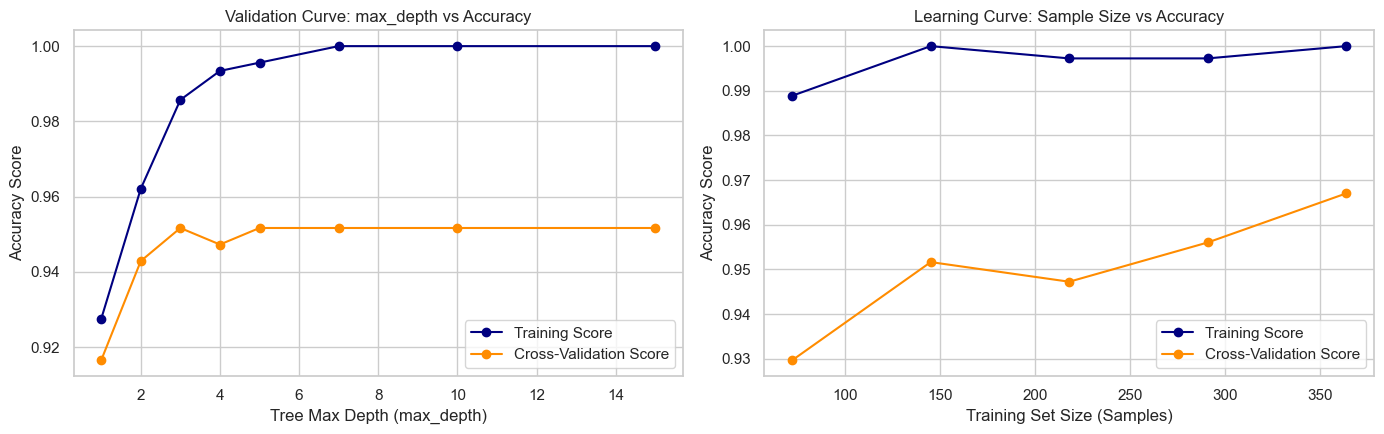

In [6]:
from sklearn.model_selection import validation_curve, learning_curve
from sklearn.svm import SVC

# --- 3.1 Validation Curve: Impact of max_depth in Random Forest ---
depth_range = np.array([1, 2, 3, 4, 5, 7, 10, 15])
train_scores_vc, test_scores_vc = validation_curve(
    RandomForestClassifier(n_estimators=50, random_state=42),
    X_train_scaled, y_train,
    param_name="max_depth",
    param_range=depth_range,
    cv=5,
    scoring="accuracy"
)

# --- 3.2 Learning Curve: Sample Size vs Performance ---
train_sizes, train_scores_lc, test_scores_lc = learning_curve(
    grid.best_estimator_,
    X_train_scaled, y_train,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=5,
    scoring="accuracy"
)

# Plotting Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# 1. Validation Curve Plot
axes[0].plot(depth_range, train_scores_vc.mean(axis=1), 'o-', color='navy', label="Training Score")
axes[0].plot(depth_range, test_scores_vc.mean(axis=1), 'o-', color='darkorange', label="Cross-Validation Score")
axes[0].set_title("Validation Curve: max_depth vs Accuracy")
axes[0].set_xlabel("Tree Max Depth (max_depth)")
axes[0].set_ylabel("Accuracy Score")
axes[0].legend(loc="lower right")

# 2. Learning Curve Plot
axes[1].plot(train_sizes, train_scores_lc.mean(axis=1), 'o-', color='navy', label="Training Score")
axes[1].plot(train_sizes, test_scores_lc.mean(axis=1), 'o-', color='darkorange', label="Cross-Validation Score")
axes[1].set_title("Learning Curve: Sample Size vs Accuracy")
axes[1].set_xlabel("Training Set Size (Samples)")
axes[1].set_ylabel("Accuracy Score")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

### 3.3 2D Hyperparameter Search Heatmap
Visualizing the cross-validation performance across combinations of `C` and `gamma` in an SVM classifier:


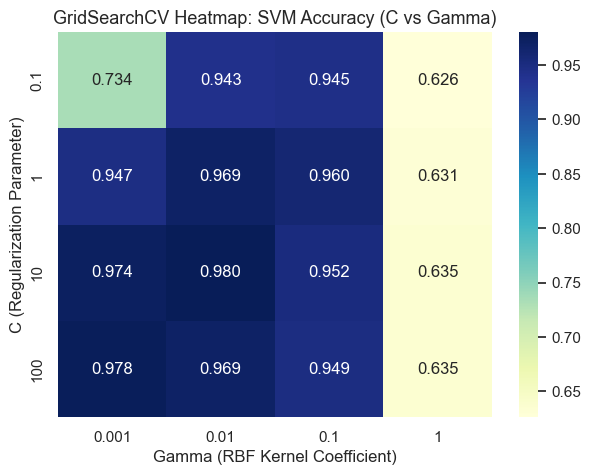

In [7]:
# Grid search over SVM C and gamma
svm_param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [0.001, 0.01, 0.1, 1]
}

svm_grid = GridSearchCV(
    estimator=SVC(kernel='rbf', random_state=42),
    param_grid=svm_param_grid,
    cv=5,
    scoring='accuracy'
)
svm_grid.fit(X_train_scaled, y_train)

# Reshape mean test scores into 2D grid matrix
scores_matrix = svm_grid.cv_results_['mean_test_score'].reshape(len(svm_param_grid['C']), len(svm_param_grid['gamma']))

plt.figure(figsize=(7, 5))
sns.heatmap(
    scores_matrix,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    xticklabels=svm_param_grid['gamma'],
    yticklabels=svm_param_grid['C']
)
plt.title("GridSearchCV Heatmap: SVM Accuracy (C vs Gamma)", fontsize=13)
plt.xlabel("Gamma (RBF Kernel Coefficient)")
plt.ylabel("C (Regularization Parameter)")
plt.show()

---
## 4. Nested Cross-Validation (Double CV)

### Why Nested Cross-Validation?
Standard cross-validation optimizes hyperparameters on the training data, but if we report `grid.best_score_` as the model's expected future accuracy, it is slightly optimistically biased.
- **Inner Loop**: Performs 3-fold or 5-fold CV to select the best hyperparameters (`GridSearchCV`).
- **Outer Loop**: Performs 5-fold CV on the entire parameter search procedure to obtain an **unbiased generalization estimate**.


In [8]:
# Inner CV: chooses hyperparameters
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
inner_grid = GridSearchCV(
    estimator=SVC(random_state=42),
    param_grid={'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']},
    cv=inner_cv,
    scoring='accuracy'
)

# Outer CV: evaluates the model selection process
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
nested_cv_scores = cross_val_score(inner_grid, X_train_scaled, y_train, cv=outer_cv, scoring='accuracy')

print("=== Nested Cross-Validation Results ===")
print("Outer Fold Accuracies:", nested_cv_scores.round(4))
print(f"Unbiased Nested CV Score: {nested_cv_scores.mean() * 100:.2f}% (± {nested_cv_scores.std() * 100:.2f}%)")

=== Nested Cross-Validation Results ===
Outer Fold Accuracies: [0.956 0.967 0.956 0.978 0.989]
Unbiased Nested CV Score: 96.92% (± 1.28%)


---
## 5. 🎓 Exam Cheat Sheet: Ready-to-Use Parameter Grids

Copy-paste parameter dictionaries for standard models during exams:

### 1. Logistic Regression
```python
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']     # Supports both l1 and l2
}
```

### 2. K-Nearest Neighbors (KNN)
```python
param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}
```

### 3. Decision Tree
```python
param_grid_dt = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
```

### 4. Random Forest
```python
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 8, None],
    'min_samples_split': [2, 5],
    'max_features': ['sqrt', 'log2']
}
```

### 5. Support Vector Machine (SVM)
```python
param_grid_svm = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto', 0.01, 0.1]
}
```

### 6. Universal Tuning Code Snippet
```python
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Configure 5-fold CV & Grid Search
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(model, param_grid, cv=cv, scoring='accuracy')
grid.fit(X_train_scaled, y_train)

# Results:
best_model = grid.best_estimator_
print("Best Params:", grid.best_params_)
print("Best Score:", grid.best_score_)
```
